In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
ticker = yf.Ticker("AAPL")

ticker

yfinance.Ticker object <AAPL>

In [4]:
df = ticker.history(
    period="1y",
    interval="1d",
    auto_adjust=True
)

df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2025-11-25 00:00:00-05:00,274.314343,279.406619,274.294423,276.008453,46914200,0.0,0.0
2025-11-26 00:00:00-05:00,275.998478,278.559563,275.669637,276.586426,33431400,0.0,0.0
2025-11-28 00:00:00-05:00,276.297421,278.031370,275.031810,277.881897,20135600,0.0,0.0
2025-12-01 00:00:00-05:00,277.044832,282.436053,275.181329,282.117157,46587700,0.0,0.0
2025-12-02 00:00:00-05:00,282.017484,286.402202,281.648773,285.196411,53669500,0.0,0.0


In [ ]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Information:")
df.info()

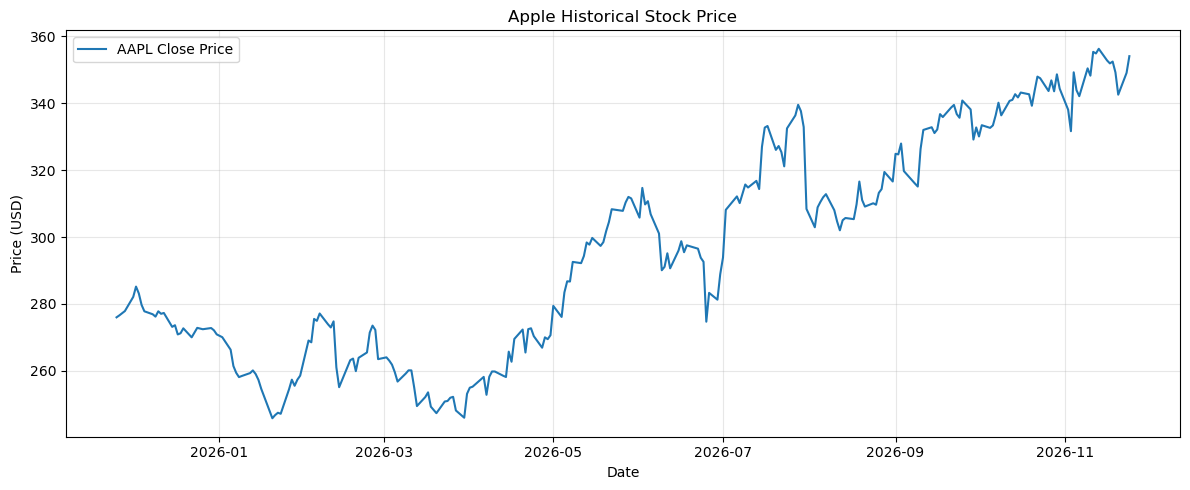

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(
    df.index,
    df["Close"],
    label="AAPL Close Price"
)

plt.title("Apple Historical Stock Price")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
SYMBOLS = ["AAPL", "NVDA", "MSFT"]

prices = yf.download(
    SYMBOLS,
    period="1y",
    interval="1d",
    auto_adjust=True,
    progress=False
)["Close"]

prices.head()

Ticker,AAPL,MSFT,NVDA
Date,,,
2025-11-25,276.008423,473.069092,177.394989
2025-11-26,276.586395,481.509155,179.829147
2025-11-28,277.881897,487.965668,176.576950
2025-12-01,282.117126,482.738953,179.489990
2025-12-02,285.196442,485.972168,181.026306


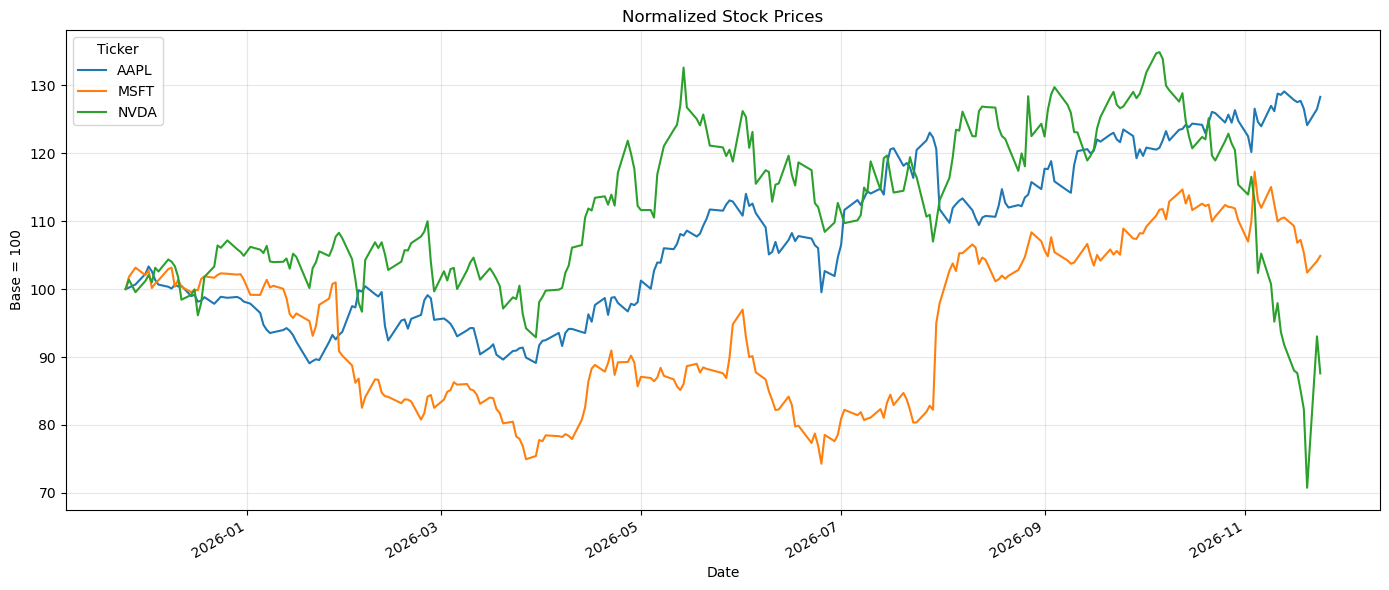

In [8]:
aligned_prices = prices.dropna()

normalized_prices = (
    aligned_prices / aligned_prices.iloc[0] * 100
)

normalized_prices.plot(
    figsize=(14, 6),
    title="Normalized Stock Prices"
)

plt.ylabel("Base = 100")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()